# BrailleLM: neural Qwen model and measured Mac results

**Capstone presentation notebook, 4 November 2026.** The actual model was trained and evaluated with `code/train.py` and `code/eval.py` on an Apple M3 Pro. This notebook executes analysis of the saved metrics and predictions. Its outputs are real calculations from those files; it does not pretend the long training happened inside Jupyter.

**Locked final score:** 216/399 strict exact (54.1%) with four-beam decoding. The plain development pilot is 109/200 (54.5%) and the extended development pilot is 93/199 (46.7%). The checkpoint and beam width were selected before the locked final evaluation.

## 1. Project method

BrailleLM asks whether adding braille-aware tokens and initializing them from corresponding print text helps a small causal language model transcribe Unicode braille. The model is Qwen2.5-0.5B-Instruct with 177 added braille tokens, BKFT initialization, and a LoRA rank-8 adapter. English comes from WikiText-2 and the original project; braille was generated by liblouis Grade 1 and round-trip filtered. The work follows the published BrailleLLM recipe on a smaller model and adds local controls. See `README.md` and `DATA_AND_EVALUATION.md`.

In [1]:
import json
from pathlib import Path
ROOT = Path.cwd()
assert (ROOT / 'results').is_dir(), 'Run notebook from neural_mac/'
manifest = json.loads((ROOT / 'experiment_manifest.json').read_text())
print('Source repository:', manifest['source_repo'])
print('Source commit:', manifest['source_commit'])
print('Host:', manifest['host'])
print('Training rows:', manifest['dataset']['scaled_train_rows'])
print('Validation rows:', manifest['dataset']['validation_rows'])

Source repository: https://github.com/Yuvraj0967/braillelm-poc
Source commit: 352fd4af6aeb808a2e97adf17781a78c866c8a9c
Host: Apple M3 Pro, 19 GB unified memory
Training rows: 15886
Validation rows: 99


## 2. Recorded experiment results

In [2]:
import json
from pathlib import Path
files = {
 'SmolLM baseline': 'eval_baseline_pilot.json',
 'SmolLM native random': 'eval_random_pilot.json',
 'SmolLM native BKFT': 'eval_bkft_pilot.json',
 'SmolLM scaled epoch 1': 'eval_scaled_epoch1_plain.json',
 'SmolLM scaled interim': 'eval_scaled_epoch2_step2000_plain.json',
 'Qwen BKFT epoch 1, greedy': 'eval_qwen_epoch1_plain.json',
 'Qwen continuation, greedy': 'eval_qwen_continue4000_plain.json',
 'Qwen continuation, 4 beams': 'eval_qwen_continue4000_beam4_plain.json',
 'Qwen extended, 4 beams': 'eval_qwen_continue4000_beam4_extended_pilot.json',
}
if (ROOT / 'results/eval_qwen_final_locked_beam4.json').exists():
    files['Qwen locked final, 4 beams'] = 'eval_qwen_final_locked_beam4.json'
metrics = {name: json.loads((ROOT / 'results' / file).read_text()) for name, file in files.items()}
print(f"{'Run':32} {'Exact':>12} {'BLEU':>8} {'CER':>8} {'Tok/cell':>9}")
print('-' * 76)
for name, d in metrics.items():
    exact = round(d['exact_match'] * d['n'])
    print(f"{name:32} {exact:>3}/{d['n']:<3} ({100*d['exact_match']:>4.1f}%) {d['sacrebleu']:>8.2f} {d['cer']:>8.4f} {d['tokens_per_cell']:>9.3f}")

Run                                     Exact     BLEU      CER  Tok/cell
----------------------------------------------------------------------------
SmolLM baseline                    0/200 ( 0.0%)     0.31   0.7258     3.000
SmolLM native random               0/200 ( 0.0%)     0.39   0.7255     0.733
SmolLM native BKFT                 2/200 ( 1.0%)    30.08   0.3751     0.733
SmolLM scaled epoch 1             17/200 ( 8.5%)    61.21   0.1614     0.733
SmolLM scaled interim             20/200 (10.0%)    58.29   0.1944     0.733
Qwen BKFT epoch 1, greedy         89/200 (44.5%)    86.66   0.0260     0.731
Qwen continuation, greedy         95/200 (47.5%)    88.25   0.0212     0.731
Qwen continuation, 4 beams       109/200 (54.5%)    90.02   0.0178     0.731
Qwen extended, 4 beams            93/199 (46.7%)    89.27   0.0253     0.759
Qwen locked final, 4 beams       216/399 (54.1%)    89.16   0.0231     0.748


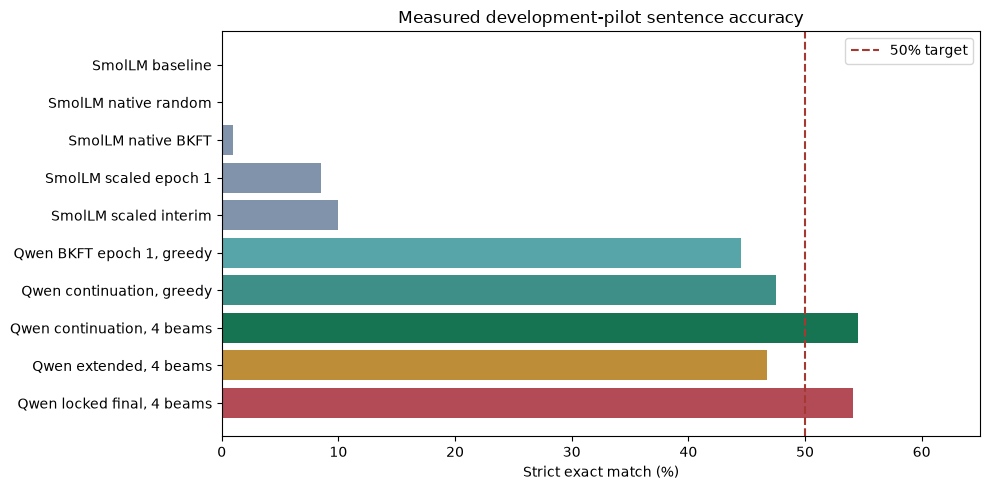

In [3]:
import matplotlib.pyplot as plt
names = list(metrics)
values = [100 * metrics[n]['exact_match'] for n in names]
colors = ['#8093aa'] * 5 + ['#58a5a9', '#3e8f87', '#167452', '#bd8d37']
if len(names) > len(colors): colors.append('#b34b56')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(names[::-1], values[::-1], color=colors[::-1])
ax.axvline(50, color='#a53831', linestyle='--', label='50% target')
ax.set_xlim(0, 65); ax.set_xlabel('Strict exact match (%)')
ax.set_title('Measured development-pilot sentence accuracy')
ax.legend(); fig.tight_layout(); plt.show()

## 3. Verify the headline directly from saved predictions

In [4]:
def read_jsonl(path):
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
plain = read_jsonl(ROOT / 'results/eval_qwen_continue4000_beam4_plain_predictions.jsonl')
extended = read_jsonl(ROOT / 'results/eval_qwen_continue4000_beam4_extended_pilot_predictions.jsonl')
for label, rows in [('Plain pilot', plain), ('Extended pilot', extended)]:
    correct = sum(row['print'] == row['prediction'] for row in rows)
    print(f'{label}: {correct}/{len(rows)} = {100*correct/len(rows):.2f}% strict exact')
print('Pooled development:', sum(r['print']==r['prediction'] for r in plain+extended),
      '/', len(plain)+len(extended))
final_predictions = ROOT / 'results/eval_qwen_final_locked_beam4_predictions.jsonl'
if final_predictions.exists():
    final_rows = read_jsonl(final_predictions)
    final_exact = sum(r['print']==r['prediction'] for r in final_rows)
    print(f'Locked final: {final_exact}/{len(final_rows)} = {100*final_exact/len(final_rows):.2f}% strict exact')
assert sum(r['print']==r['prediction'] for r in plain) == 109
assert sum(r['print']==r['prediction'] for r in extended) == 93

Plain pilot: 109/200 = 54.50% strict exact
Extended pilot: 93/199 = 46.73% strict exact
Pooled development: 202 / 399
Locked final: 216/399 = 54.14% strict exact


In [5]:
print('Correct examples:')
for row in [r for r in plain if r['print'] == r['prediction']][:2]:
    print('  ', row['prediction'])
print('\nError examples (reference -> model):')
for row in [r for r in plain if r['print'] != r['prediction']][:3]:
    print('  REF:', row['print'])
    print('  HYP:', row['prediction'])

Correct examples:
   The battle extended well into the night.
   Du subsequently based himself in Sichuan for most of the next five years.

Error examples (reference -> model):
  REF: The names Stegocephalia and Labyrinthodontia were used interchangeably to refer to the order in which it belonged.
  HYP: The names Stegocephalia and Labyrinthodonta were used interchangably to refer to the order in which it belonged.
  REF: He has been honored with the Roberto Clemente Award and the Branch Rickey Award for his humanitarian work.
  HYP: He has been honored with the Roberto Clemence Award and the Branch Rickey Award for his humanitarian work.
  REF: The North Koreans began crossing the Naktong River under cover of darkness at certain points.
  HYP: The North Koreans began crossing the Naktoang River under cover of darkness at certain points.


## 4. Data separation

The pilots are development sets. We selected the checkpoint and beam width using development observations. The separate 399-sentence final file was evaluated after selection.

In [6]:
train = read_jsonl(ROOT / 'data/train.jsonl')
val = read_jsonl(ROOT / 'data/validation.jsonl')
final = read_jsonl(ROOT / 'data/final_test.jsonl')
sets = {'train': {r['print'] for r in train},
        'validation': {r['print'] for r in val},
        'plain pilot': {r['print'] for r in plain},
        'extended pilot': {r['print'] for r in extended},
        'final': {r['print'] for r in final}}
for left, right in [('train','validation'),('train','plain pilot'),
                    ('train','extended pilot'),('train','final'),
                    ('plain pilot','final'),('extended pilot','final')]:
    overlap = len(sets[left] & sets[right])
    print(f'{left} vs {right}: {overlap} identical sentences')
    assert overlap == 0

train vs validation: 0 identical sentences
train vs plain pilot: 0 identical sentences
train vs extended pilot: 0 identical sentences
train vs final: 0 identical sentences
plain pilot vs final: 0 identical sentences
extended pilot vs final: 0 identical sentences


## 5. Locked final audit and unseen-word check

In [7]:
audit = json.loads((ROOT / 'results/final_independent_audit.json').read_text())
assert audit['labels_match_test_file_in_order']
assert audit['saved_metrics_recomputed']
for label, key in [('All final', 'all_399'),
                   ('Contains training-unseen word', 'contains_training_unseen_word'),
                   ('All words in training vocabulary', 'all_words_in_training_vocabulary')]:
    d = audit[key]
    print(f"{label}: {d['strict_exact_count']}/{d['n']} = {100*d['strict_exact_rate']:.2f}% strict exact")
print('Final 95% Wilson interval:', audit['all_399']['strict_exact_wilson_95'])

All final: 216/399 = 54.14% strict exact
Contains training-unseen word: 116/263 = 44.11% strict exact
All words in training vocabulary: 100/136 = 73.53% strict exact
Final 95% Wilson interval: [0.4923, 0.5896]


## 6. Training and inference commands

The Mac training used `code/train.py` with AdamW, LoRA rank 8, batch 2, gradient accumulation 8, learning rate 1e-4, max length 256, and three saved stages: 7,943 + 4,000 + 4,000 microbatches. The exact reproduction commands and checkpoint chain are in [`TRAINING_AND_REPRODUCTION.md`](TRAINING_AND_REPRODUCTION.md). To evaluate the released checkpoint:

```bash
python code/eval.py --ckpt model --base_model Qwen/Qwen2.5-0.5B-Instruct --test_file data/pilot_plain.jsonl --max_new 96 --num_beams 4 --out rerun_plain.json --predictions rerun_plain_predictions.jsonl
```

The checkpoint archive is on the linked GitHub release. These notebook cells are analytical outputs from saved runs; they do not re-execute the long model training.

## 7. Presentation conclusion and limits

The measured neural checkpoint scored 216/399 (54.1%) strict exact on the locked final test. The 263 final sentences with at least one training-unseen word scored 116/263 (44.1%), while the remaining 136 scored 100/136 (73.5%). The 95% Wilson interval for the overall final rate is 49.2%–59.0%. Remaining errors often involve proper names and rare spellings. The braille is machine-generated clean Grade 1; no human-entered, Grade 2, noisy, or OCR input is validated. The separate cell-to-character specialist's stronger results are not scores for this neural model.